In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import ast
import scipy
import mdtraj as md
from typing import Dict, Tuple
import os
from sklearn.linear_model import LinearRegression
import sys
import pyblock
bme_dir = '/projects/lindorff_group/people/thd711/HDX_project/code/BME/' # replace this with your local copy of the BME code
sys.path.append(bme_dir)
import BME as BME


# matplotlib settings
# --- Publication style settings ---
plt.rcParams.update({
    # Font
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "text.usetex": False,

    # Editable, Affinity-compatible font embedding
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    # Figure
    "figure.figsize": (6, 4),
    "figure.dpi": 150,

    # Axes
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.linewidth": 1.2,
    "axes.grid": True,
    "grid.linestyle": "--",
    "grid.alpha": 0.7,

    # Ticks
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,

    # Lines
    "lines.linewidth": 2,
    "lines.markersize": 6,

    # Legend
    "legend.fontsize": 10,
    "legend.frameon": False
})

def find_xtc_filenames(path_to_dir, suffix=".xtc"):
    filenames = os.listdir(path_to_dir)
    return [filename for filename in filenames if filename.endswith(suffix)]

# --- Utility functions ---
def RMSE(actual, predicted):
    actual = np.array(actual)
    predicted = np.array(predicted)
    return np.sqrt(np.mean((actual - predicted)**2))

# Function to calculate helical fraction
def helical_fraction(ss_line):
    helix_chars = {'H', 'G', 'I'}
    n_residues = len(ss_line)
    n_helical = sum(1 for c in ss_line if c in helix_chars)
    return n_helical / n_residues

# Function to calculate per-residue helicity per frame
def dssp_to_helicity(dssp_lines):
    """
    Convert DSSP strings into a binary helicity matrix.
    
    Parameters
    ----------
    dssp_lines : list of str
        Each entry corresponds to one frame.
        Each string is the DSSP assignment per residue for that frame.
    
    Returns
    -------
    helicity : np.ndarray
        Array of shape (n_frames, n_residues).
        1 = helix ('H', 'G', 'I'), 0 = non-helix.
    """
    helix_codes = {'H', 'G', 'I'}
    
    n_frames = len(dssp_lines)
    n_residues = len(dssp_lines[0])
    
    helicity = np.zeros((n_frames, n_residues), dtype=int)
    
    for i, line in enumerate(dssp_lines):
        helicity[i, :] = [1 if c in helix_codes else 0 for c in line]
    
    return helicity

# functions for analysis of chemical shifts
# functions for chemical shift analysis
# Constants
# from here : https://link.springer.com/article/10.1007/s10858-010-9433-9 (average prediction error of the forward model)
CS_UNCERTAINTIES = {
    "Sparta+": {"C": 1.09, "CA": 0.94, "CB": 1.14, "N": 2.45, "H": 0.49, "HA": 0.25}
}

POTENCI_UNCERTAINTIES = {"C": 0.1861, "CA": 0.1862, "CB": 0.1677, "N": 0.5341, "H": 0.0735, "HA": 0.0319, "HB": 0.0187}

AA_dict = {
    "A": "ALA",  # Alanine
    "R": "ARG",  # Arginine
    "N": "ASN",  # Asparagine
    "D": "ASP",  # Aspartic Acid
    "C": "CYS",  # Cysteine
    "E": "GLU",  # Glutamic Acid
    "Q": "GLN",  # Glutamine
    "G": "GLY",  # Glycine
    "H": "HIS",  # Histidine
    "I": "ILE",  # Isoleucine
    "L": "LEU",  # Leucine
    "K": "LYS",  # Lysine
    "M": "MET",  # Methionine
    "F": "PHE",  # Phenylalanine
    "P": "PRO",  # Proline
    "S": "SER",  # Serine
    "T": "THR",  # Threonine
    "W": "TRP",  # Tryptophan
    "Y": "TYR",  # Tyrosine
    "V": "VAL",  # Valine
}

# atom types to use during reweighting: choose from [ HA CA HN N C CB ]
ATOM_TYPES = ["CA", "HA", "CB", "HN", "N", "C", "H"] # HN and H present because "H" is used in potenci shift tables
ATOM_TYPES = ["CA"] 

def load_experimental_shifts(path: str, ATOM_TYPES) -> Dict[Tuple[int, str], float]:
    """Load experimental chemical shifts. Returns first column is 'resSeq', second is 'name', third is 'value'."""
    df = pd.read_csv(path, delim_whitespace=True)
    residues = []
    names = []
    values = []
    for i in range(len(df)):
        res = int(df['#RESID'][i])
        for col in df.columns[2:]:
            if col in ATOM_TYPES: # only including specified nuclei
                if col=='HN':
                    try:
                        value = float(df[col][i])
                        if value>0:
                            residues.append(res)
                            names.append('H') # rename HN to H
                            values.append(value)
                    except:
                        continue
                else:
                    try:
                        value = float(df[col][i])
                        if value>0:
                            residues.append(res)
                            names.append(col)
                            values.append(value)
                    except:
                        continue
            else:
                continue
    return {(int(res), str(name)): float(value) for res, name, value in zip(residues, names, values)}

def load_and_filter_experimental_shifts(path: str, bmrb_stats_path: str, sigma_cutoff = 3.0, ATOM_TYPES = ATOM_TYPES) -> Dict[Tuple[int, str], float]:
    """Load experimental chemical shifts. Returns first column is 'resSeq', second is 'name', third is 'value'."""
    df = pd.read_csv(path, delim_whitespace=True)
    bmrb = pd.read_csv(bmrb_stats_path)
    residues = []
    names = []
    values = []
    for i in range(len(df)):
        res = int(df['#RESID'][i])
        resname = str(df['RESNAME'][i])
        if len(resname)==1:
            resname = AA_dict[resname] # convert to 3-letter code if 1-letter
        for col in df.columns[2:]:
            if col in ATOM_TYPES: # only including specified nuclei
                try:
                    value = float(df[col][i])
                    if value>0:
                        # extract bmrb avg and sd
                        if col=='HN':
                            row = bmrb[(bmrb["comp_id"] == resname) & (bmrb["atom_id"] == 'H')]
                            bmrb_mu = row["avg"].values[0]
                            bmrb_sd = row["std"].values[0]
                            if np.abs(value - bmrb_mu) < bmrb_sd * sigma_cutoff:
                                residues.append(res)
                                names.append('H') # rename HN to H
                                values.append(value)
                        else:
                            row = bmrb[(bmrb["comp_id"] == resname) & (bmrb["atom_id"] == col)]
                            bmrb_mu = row["avg"].values[0]
                            bmrb_sd = row["std"].values[0]
                            if np.abs(value - bmrb_mu) < bmrb_sd * sigma_cutoff:
                                residues.append(res)
                                names.append(col)
                                values.append(value)
                except:
                    continue
            else:
                continue
    return {(int(res), str(name)): float(value) for res, name, value in zip(residues, names, values)}

def load_potenci_shifts(path: str, ATOM_TYPES = ATOM_TYPES) -> Dict[Tuple[int, str], float]:
    """Load experimental chemical shifts. Returns first column is 'resSeq', second is 'name', third is 'value'."""
    df = pd.read_csv(path, delim_whitespace=True)
    residues = []
    names = []
    values = []
    for i in range(len(df)):
        res = int(df['#NUM'][i])
        for col in df.columns[2:]:
            if col in ATOM_TYPES: # only including specified nuclei
                try:
                    value = float(df[col][i])
                    if value>0:
                        residues.append(res)
                        names.append(col)
                        values.append(value)
                except:
                    continue
            else:
                continue
    return {(int(res), str(name)): float(value) for res, name, value in zip(residues, names, values)}

def load_generated_shifts(path: str) -> pd.DataFrame:
    """
    Load generated shifts from a CSV file.
    Assumes columns: resSeq, name, 0, 1, 2, ..., representing one residue/atom per row and frames across columns.
    Returns DataFrame indexed by (resSeq, name), with frames as columns.
    """
    df = pd.read_csv(path)
    df["resSeq"] = df["resSeq"].astype(int)
    df["name"] = df["name"].astype(str)
    df.set_index(["resSeq", "name"], inplace=True)
    return df

def standardize_deltas(gen_df: pd.DataFrame, exp_dict: Dict[Tuple[int, str], float],
                       predictor: str = "Sparta+", avg_gscore: float = None) -> Tuple[np.ndarray, list]:
    cs_uncertainties = CS_UNCERTAINTIES[predictor]
    keys = sorted(set(exp_dict).intersection(set(gen_df.index)))

    if avg_gscore is None:
        std_devs = np.array([cs_uncertainties[a] for (_, a) in keys]).reshape(-1, 1)
    else:
        std_devs = np.array([
            POTENCI_UNCERTAINTIES[a] + ( cs_uncertainties[a] - POTENCI_UNCERTAINTIES[a] ) * (1 - avg_gscore)
            for r, a in keys
        ]).reshape(-1, 1)
    
    exp_vals = np.array([exp_dict[k] for k in keys]).reshape(-1, 1)
    gen_vals = gen_df.loc[keys].values  # shape: (n_obs, n_frames)
    std_delta = (gen_vals - exp_vals) / std_devs
    return std_delta, keys, exp_vals, gen_vals, std_devs

# function to calculate the difference between experiment and simulation: CALC - EXP
def raw_diff(gen_df: pd.DataFrame, exp_dict: Dict[Tuple[int, str], float]):
    keys = sorted(set(exp_dict).intersection(set(gen_df.index)))
    exp_vals = np.array([exp_dict[k] for k in keys]).reshape(-1, 1)
    gen_vals = gen_df.loc[keys].values  # shape: (n_obs, n_frames)
    diff = gen_vals - exp_vals

    return diff, keys

def get_RMSE_cs(
    std_delta_cs: np.ndarray,  # shape (n_obs, n_samples)
    weights: np.ndarray = None,  # shape (n_samples,)
    order: int = 2,  # order of the norm
) -> float:
    """Root Mean Square Error."""
    assert len(std_delta_cs.shape) == 2
    mask_nan = ~np.isnan(std_delta_cs).any(axis=0)
    if weights is None:
        return np.linalg.norm(np.average(std_delta_cs[:, mask_nan], axis=1), ord=order) / np.power(
            len(std_delta_cs),
            1 / order,
        )
    mask_nan_weights = ~np.isnan(weights)
    if weights[mask_nan_weights & (~mask_nan)].sum() != 0:
        print("+++ WARNING: samples with NaN chemical shifts should have 0 weight")
    mask_nan = mask_nan & mask_nan_weights
    if not mask_nan.any():  # this happens if the optimization failed
        return np.nan
    return np.linalg.norm(
        np.average(std_delta_cs[:, mask_nan], weights=weights[mask_nan], axis=1),
        ord=order,
    ) / np.power(len(std_delta_cs), 1 / order)

path = '../'

# SAXS functions
def parse_gensaxs_dat(filename: str):

    df = pd.read_csv(filename)
    # drop index column
    df = df.drop(columns=["Unnamed: 0"])
    q = np.array(df.columns).astype(float) # shape (n_obs, )
    I_gen = np.array(df) # shape (n_samples, n_obs)

    return q, I_gen

# function to fit saxs curves to experimental curves & calculate chi2
def fit_SAXS(I_gen, I_exp, I_exp_err):

    wlr = 1/(I_exp_err**2)

    model = LinearRegression()
    model.fit(I_gen.reshape(-1,1),I_exp,wlr)
    alpha = model.coef_[0]
    beta = model.intercept_

    scaled = alpha*I_gen+beta

    # Calculate chi^2
    N = len(I_gen)
    chi2 = ((I_exp - scaled)**2 / I_exp_err**2).sum()
    chi2red = chi2/N

    return chi2red, scaled, alpha, beta

def find_elbow(x, y):
    # Convert to numpy arrays
    x = np.array(x)
    y = np.array(y)

    # Sort x (and y) if needed, but keep track of original indices
    if not np.all(np.diff(x) >= 0):
        idx_sort = np.argsort(x)
        x_sorted = x[idx_sort]
        y_sorted = y[idx_sort]
    else:
        idx_sort = np.arange(len(x))
        x_sorted, y_sorted = x, y

    # Line between first and last point
    p1 = np.array([x_sorted[0], y_sorted[0]])
    p2 = np.array([x_sorted[-1], y_sorted[-1]])
    line_vec = p2 - p1
    line_vec_norm = line_vec / np.linalg.norm(line_vec)

    # Distances from each point to the line
    vec_from_p1 = np.vstack([x_sorted - p1[0], y_sorted - p1[1]]).T
    proj_len = np.dot(vec_from_p1, line_vec_norm)
    proj_point = np.outer(proj_len, line_vec_norm) + p1
    dist = np.linalg.norm(vec_from_p1 - (proj_point - p1), axis=1)

    # Elbow = point with maximum distance
    idx_elbow_sorted = np.argmax(dist)
    idx_elbow_original = idx_sort[idx_elbow_sorted]

    return idx_elbow_original

outpath='./'
data_path = '../../MD_DATA/'
exp_data_path = '../../ORTHOGONAL_EXP_DATA/'


In [2]:
protein = 'AAQAA3'
traj_names = np.sort(find_xtc_filenames(data_path+f'./{protein}/'))

# load CS data
all_types = ['CA', 'CB', 'HA', 'C', 'HN', 'H', 'N']
for i in range(len(traj_names)):
    if i==0:
        gen_df = load_generated_shifts(data_path+f'./{protein}/CS/CS_{traj_names[i][:-4]}.csv')
    else:
        tmp_df = load_generated_shifts(data_path+f'./{protein}/CS/CS_{traj_names[i][:-4]}.csv')
        gen_df= pd.concat([gen_df, tmp_df], axis=1, join = 'outer', ignore_index=True)

# experimental CS data
exp_dict = load_and_filter_experimental_shifts(exp_data_path+f'{protein}/CS.dat', exp_data_path+'./cs_stat_aa_filt.csv', ATOM_TYPES=all_types)

# average gscore for CS error scaling
avg_gscore = 0.5

# get standardised deltas
std_delta_cs, keys, expCS, calcCS, expCS_err = standardize_deltas(gen_df, exp_dict, predictor = 'Sparta+', avg_gscore=avg_gscore)
calcCS = calcCS.T
expCS = expCS[:,0]
expCS_err = expCS_err[:,0]
print(calcCS.shape)
print(expCS.shape)
print(expCS_err.shape)

# make prior weights uniform 
w0 = np.ones(calcCS.shape[0])/calcCS.shape[0]

print('Data is ready')

(246694, 13)
(13,)
(13,)
Data is ready


In [ ]:
# BME for CS

thetas = np.geomspace(1e4, 1e-2, 40)

# concatenate stuff
all_exp = expCS.copy()
all_err = expCS_err.copy()
all_gen = calcCS.copy()
bounds = np.zeros(len(all_exp)).astype(int)
labels = np.arange(len(all_exp)) # restraint indices

wopt_array = []
CS_RMSE = []
loss = []
neffs = []
final_thetas = []

for theta in thetas:
    # run BME
    EXP = np.vstack([all_exp.copy(), all_err.copy(), bounds.copy()]).T
    rew_obj = BME.Reweight("BME", w0=np.copy(w0)) # always start from prior weights
    rew_obj.load_array(labels,EXP,all_gen.copy())
    chi2_before, chi2_after, phi = rew_obj.fit(theta=theta)

    # get weights
    w_curr = rew_obj.get_weights()

    if np.isnan(np.sum(w_curr)):
        continue

    # save weights from this theta
    final_thetas.append(theta)
    wopt_array.append(w_curr)
    loss.append(chi2_after)
    neffs.append(phi)
    print(chi2_after)

    # CS/SAXS stats
    CS_RMSE.append(get_RMSE_cs(std_delta_cs=std_delta_cs, weights=w_curr))

# save all data
np.savetxt(outpath+'rew_thetas.txt', final_thetas)
np.savetxt(outpath+'rew_neffs.txt', neffs)
np.savetxt(outpath+'rew_loss.txt', loss)
np.savetxt(outpath+'rew_CS_RMSE.txt', CS_RMSE)
np.save(outpath+'rew_wopt_array.npy', wopt_array)

print('Done with all thetas.')

3.1932592457279183
3.190288151367265
3.186054620783932
3.179956368625849
3.171333722787054
3.1590504642763166
3.141556827214994
3.1166717092955643
3.0812642918286985
3.03097719655535
2.9597488086206982
2.8593673619510485
2.719249849621465
2.5271557238337428
2.272306305346834
1.9526531108168699
1.585506387128554
1.2100484401242515
0.8730860536692753
0.6062314664502465
0.41480059971880817
0.2867899200571711
0.20384828090469798
0.14983887768080198
0.11267833280833763
0.08525824728374101
0.06371138954905345
0.046383125286681266
0.032608070830782876
0.022005324676109342
0.014243241923216018
0.008823847093273798
0.005245717131757398
0.00299926754146193
0.0016599911039432147
0.0008969831086920221
0.00047000790395197473
0.0002462964021169741
0.0001260879470508252
6.430464072844832e-05
Done with all thetas.


findfont: Font family ['Times New Roman'] not found. Falling back to DejaVu Sans.


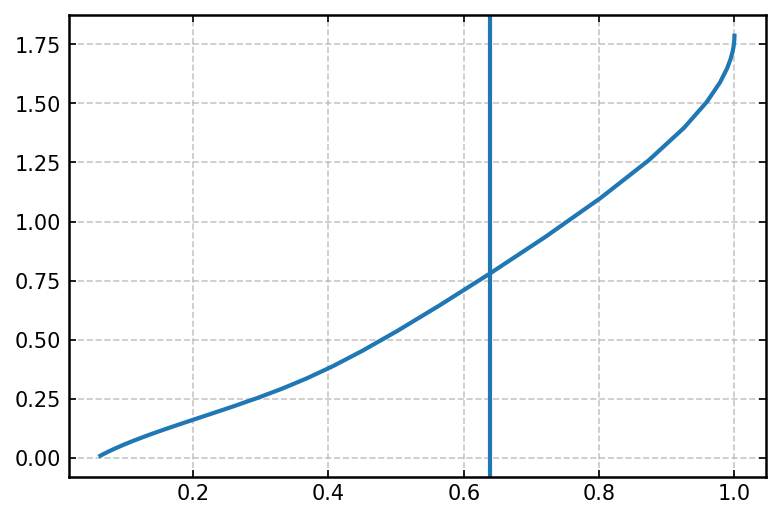

In [3]:
final_thetas = np.loadtxt(outpath+'rew_thetas.txt')
neffs = np.loadtxt(outpath+'rew_neffs.txt')
loss = np.loadtxt(outpath+'rew_loss.txt')
CS_RMSE = np.loadtxt(outpath+'rew_CS_RMSE.txt')
wopt_array = np.load(outpath+'rew_wopt_array.npy')

elidx = find_elbow(neffs, CS_RMSE)+1
plt.plot(neffs, CS_RMSE)
plt.axvline(neffs[elidx])


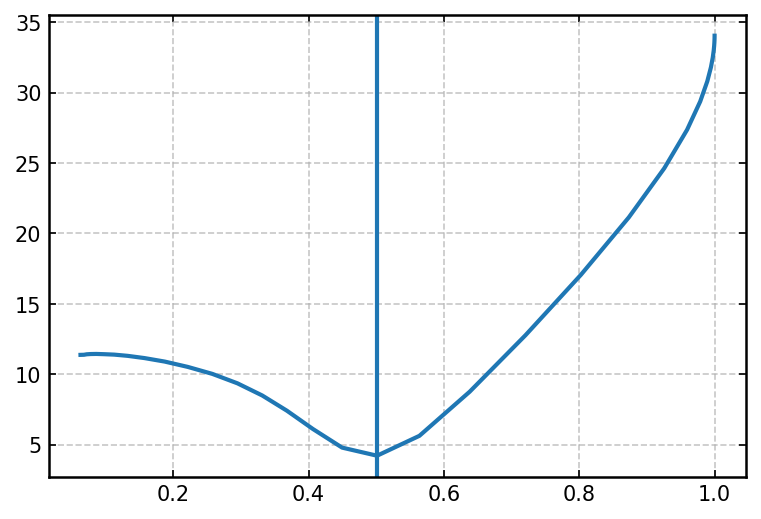

In [4]:
# comparison with helix propensity (sanity-check)

# load dssp data
'''
with open(f'../../MD_DATA/{protein}/dssp.dat') as f:
    dssp = [line.strip() for line in f]
dssp =  np.array(dssp)
H = dssp_to_helicity(dssp)*100
'''
protein = 'AAQAA3'
traj_names = np.sort(find_xtc_filenames(data_path+f'./{protein}/'))
for i, traj in enumerate(traj_names):
    number = traj.split('.')[0][-1]
    with open(f'../../MD_DATA/{protein}/dssp{number}.dat') as f:
        dssp = [line.strip() for line in f]
    dssp =  np.array(dssp)
    if i==0:
        H = dssp_to_helicity(dssp)*100
    else:
        tmpH = dssp_to_helicity(dssp)*100
        H = np.concatenate((H, tmpH), axis=0)

# experimental helicity
exp_helix = np.loadtxt('../../ORTHOGONAL_EXP_DATA/AAQAA3/helicity.dat')
exp_helix_residues = exp_helix[:,0].astype(int)

all_residues = np.arange(1,18)

wopt_array = np.load(outpath+f"rew_wopt_array.npy")
wopt = wopt_array

helix_indices = np.array([list(all_residues).index(res) for res in exp_helix_residues])


# calculate RMSE to validation data
validation_rmse = []
for W in wopt_array:
    avgH = np.average(H,weights=W,axis=0)
    validation_rmse.append(RMSE(avgH[helix_indices], exp_helix[:,1]))

min_idx = np.where(validation_rmse==np.min(validation_rmse))[0][0]


plt.plot(neffs, validation_rmse)
plt.axvline(neffs[min_idx])

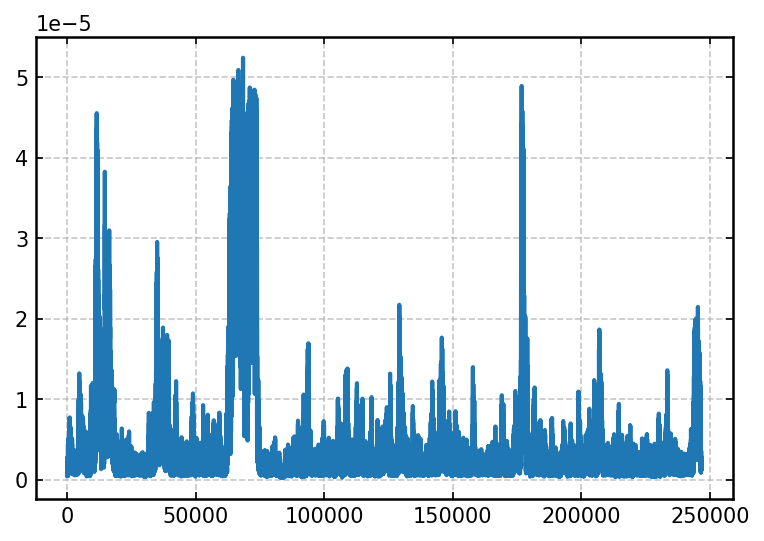

In [5]:
plt.plot(wopt_array[min_idx])

<BarContainer object of 15 artists>

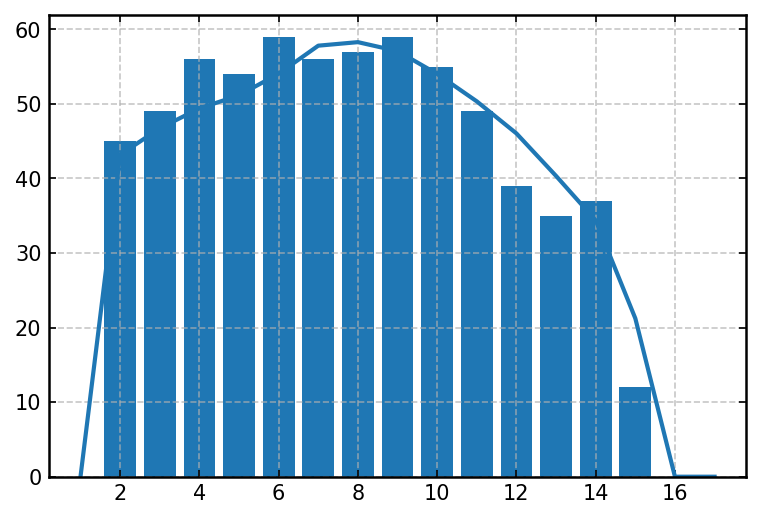

In [6]:

plt.plot(all_residues, np.average(H, axis=0, weights=wopt_array[min_idx]))
plt.bar(exp_helix_residues, exp_helix[:,1])

In [16]:
np.save(outpath+'final_wopt.npy', wopt_array[min_idx])

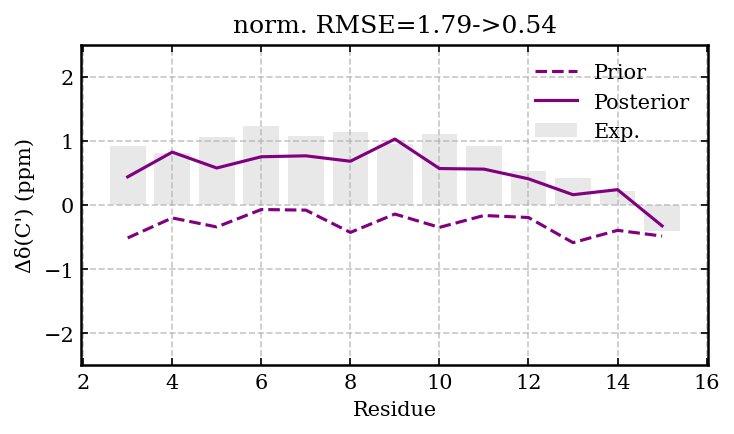

In [22]:
# plot chemical shifts

# Load data
wopt = np.load("final_wopt.npy")
prior_weights = np.ones(wopt.shape[0]) / wopt.shape[0]

nucleus = 'C'
all_types = ['C']
label_dict = {'CA': 'Cα', 'HA': 'Hα', 'CB': 'Cβ', 'C': "C'"}
axlim_dict = {'CA': 2.5, 'HA': 1, 'CB': 2.5, 'C': 2.5}

# get standardised deltas
std_delta_cs, keys, expCS, calcCS, expCS_err = standardize_deltas(gen_df, exp_dict, predictor='Sparta+', avg_gscore=avg_gscore)

# load RC shifts
potenci = load_potenci_shifts(f'../../ORTHOGONAL_EXP_DATA/potenci_shifts/{protein}_RCshifts.dat', ATOM_TYPES=all_types)

# collect POTENCI shifts for selected nucleus
potenci_residues = []
potenci_shifts = []

for key in potenci:
    if key[1] == nucleus:
        potenci_residues.append(key[0])
        potenci_shifts.append(potenci[key])

potenci_residues = np.array(potenci_residues)
potenci_shifts = np.array(potenci_shifts)

# collect experimental shifts for selected nucleus
exp_residues = []
exp_shifts = []

for key in exp_dict:
    if key[1] == nucleus:
        exp_residues.append(key[0])
        exp_shifts.append(exp_dict[key])

exp_residues = np.array(exp_residues)
exp_shifts = np.array(exp_shifts)

# make residue -> shift lookup dictionaries
potenci_lookup = {res: shift for res, shift in zip(potenci_residues, potenci_shifts)}
exp_lookup = {res: shift for res, shift in zip(exp_residues, exp_shifts)}

# residues that have experimental and POTENCI values
common_residues = np.intersect1d(potenci_residues, exp_residues)

# further restrict to residues that also have calculated chemical shifts
calc_vals = []
calc_residues = []

for res in common_residues:
    try:
        vals = np.asarray(gen_df.loc[res, nucleus], dtype=float)
        calc_vals.append(vals)
        calc_residues.append(res)
    except (KeyError, TypeError, ValueError):
        continue

calc_residues = np.array(calc_residues)
calc_vals = np.array(calc_vals).T

# align experimental and POTENCI shifts exactly to calc_residues
exp_for_calc = np.array([exp_lookup[res] for res in calc_residues])
potenci_for_calc = np.array([potenci_lookup[res] for res in calc_residues])

# experimental secondary shifts
SSexp = exp_for_calc - potenci_for_calc

# average prior
prior = np.average(calc_vals, axis=0, weights=prior_weights)
SSprior = prior - potenci_for_calc
CS_RMSE_prior = get_RMSE_cs(std_delta_cs, weights=prior_weights)

# average posterior
post = np.average(calc_vals, axis=0, weights=wopt)
SSpost = post - potenci_for_calc
CS_RMSE_post = get_RMSE_cs(std_delta_cs, weights=wopt)

# plot secondary shifts: experiment vs calculated prior/posterior
plt.figure(figsize=(5, 3))

plt.title(f"norm. RMSE={CS_RMSE_prior:.2f}->{CS_RMSE_post:.2f}")

plt.bar(calc_residues, SSexp, color='lightgrey', alpha=0.5, label='Exp.')
plt.plot(calc_residues, SSprior, color='purple', label='Prior', linewidth=1.5, linestyle='dashed')
plt.plot(calc_residues, SSpost, color='purple', label='Posterior', linewidth=1.5)

plt.ylim(-axlim_dict[nucleus], axlim_dict[nucleus])
plt.xlabel("Residue")
plt.ylabel(f"Δδ({label_dict[nucleus]}) (ppm)")
plt.legend()

plt.tight_layout()
plt.savefig(f"{protein}_{nucleus}_CS_prior_post.pdf")
plt.show()

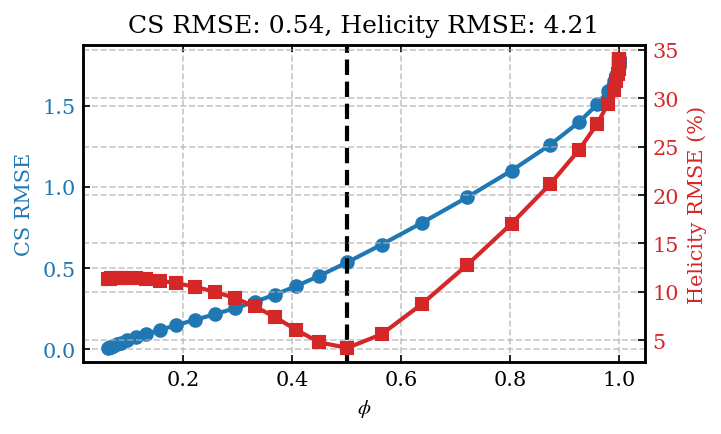

In [27]:
# cross-validation: active CS agreement vs held-out helicity agreement

# load reweighting data
wopt_array = np.load(outpath + 'rew_wopt_array.npy')
CS_RMSE = np.loadtxt(outpath + 'rew_CS_RMSE.txt')
neffs = np.loadtxt(outpath + 'rew_neffs.txt')

# load DSSP data
protein = 'AAQAA3'
traj_names = np.sort(find_xtc_filenames(data_path + f'./{protein}/'))

for i, traj in enumerate(traj_names):
    number = traj.split('.')[0][-1]

    with open(f'../../MD_DATA/{protein}/dssp{number}.dat') as f:
        dssp = np.array([line.strip() for line in f])

    tmpH = dssp_to_helicity(dssp) * 100

    if i == 0:
        H = tmpH
    else:
        H = np.concatenate((H, tmpH), axis=0)

# experimental helicity
exp_helix = np.loadtxt('../../ORTHOGONAL_EXP_DATA/AAQAA3/helicity.dat')
exp_helix_residues = exp_helix[:, 0].astype(int)

all_residues = np.arange(1, 18)
helix_indices = np.array([list(all_residues).index(res) for res in exp_helix_residues])

# calculate validation RMSE for each reweighted ensemble
validation_rmse = []

for W in wopt_array:
    avgH = np.average(H, weights=W, axis=0)
    validation_rmse.append(RMSE(avgH[helix_indices], exp_helix[:, 1]))

validation_rmse = np.array(validation_rmse)

# minimum validation RMSE
min_idx = np.where(validation_rmse == np.min(validation_rmse))[0][0]

# create figure
fig, ax1 = plt.subplots(figsize=(5, 3))

# CS RMSE
ax1.plot(neffs, CS_RMSE, 'o-', color='tab:blue')
ax1.set_xlabel(r"$\phi$")
ax1.set_ylabel('CS RMSE', color='tab:blue')
ax1.tick_params(axis='y', labelcolor='tab:blue')

# helicity validation RMSE
ax2 = ax1.twinx()
ax2.plot(neffs, validation_rmse, 's-', color='tab:red')
ax2.set_ylabel('Helicity RMSE (%)', color='tab:red')
ax2.tick_params(axis='y', labelcolor='tab:red')

# mark minimum validation RMSE
ax1.axvline(neffs[min_idx], color='black', linestyle='dashed')

# title
ax1.set_title(f'CS RMSE: {CS_RMSE[min_idx]:.2f}, Helicity RMSE: {validation_rmse[min_idx]:.2f}')

plt.tight_layout()
plt.savefig(f'{protein}_CS_vs_Helicity_RMSE.pdf')
plt.show()